# Event-locked kernels, M2: LEC

Loads and plots only. Numbers come from `run_event_kernels.py` and `run_population_drift.py`, one
job per recday through `sbatch_files/submit_event_kernels.sh`, merged with `--merge`. Write-ups:
`code/EVENT_KERNELS.md` (2026-10-12 entry) and `code/POPULATION_DRIFT.md`.

- Design: `kin='strict'`; analysis sessions are ABCD sessions with >= 10 trials (LEC also >= 5 as a
  sensitivity arm); leave one session out; Freedman-Lane, n_perm 100.
- A unit is **locked** to a block when p < 0.05 and its held-out cpd > 0. The exact null rate of
  p < 0.05 at n_perm 100 is 5/101.
- Every summary is per mouse: the recday mean, then the mouse mean (the `anatomy_split` convention).


In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs and merges instead
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import event_kernels_plots as P
%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
fig_path = lambda name: os.path.join(P.FIG_DIR, name)
drift_path = lambda name: os.path.join(P.DRIFT_FIG_DIR, name)
L = P.load_latest(os.path.join(P.STAGE1_DIR, 'stage1_lec_kin-strict_mt10_np100'))
L5 = P.load_latest(os.path.join(P.STAGE1_DIR, 'stage1_lec_kin-strict_mt5_np100'))
D10 = P.load_latest(os.path.join(P.DRIFT_DIR, 'drift_lec_mt10'))
D5 = P.load_latest(os.path.join(P.DRIFT_DIR, 'drift_lec_mt5'))
print(*(os.path.basename(m['_path']) for m in (L, L5, D10, D5)), sep='\n')

stage1_lec_kin-strict_mt10_np100.pkl
stage1_lec_kin-strict_mt5_np100.pkl
drift_lec_mt10.pkl
drift_lec_mt5.pkl


## Run summary at both thresholds

In [2]:
pd.concat([P.table_run_summary({'LEC >= 10': L}), P.table_run_summary({'LEC >= 5': L5})])

,dataset,anchor,recdays,skipped,units,sessions,rank_only_duplicates,r2_cv_median_of_recdays,reset_skipped,n_perm,kin,min_trials
0,LEC >= 10,entry,25,1,2742,135,True,0.050682,0,100,strict,10
1,LEC >= 10,first_A,25,1,2742,135,False,0.051299,0,100,strict,10
0,LEC >= 5,entry,25,0,2851,164,False,0.053819,0,100,strict,5
1,LEC >= 5,first_A,25,0,2851,164,False,0.053688,0,100,strict,5


## F11. Per recday

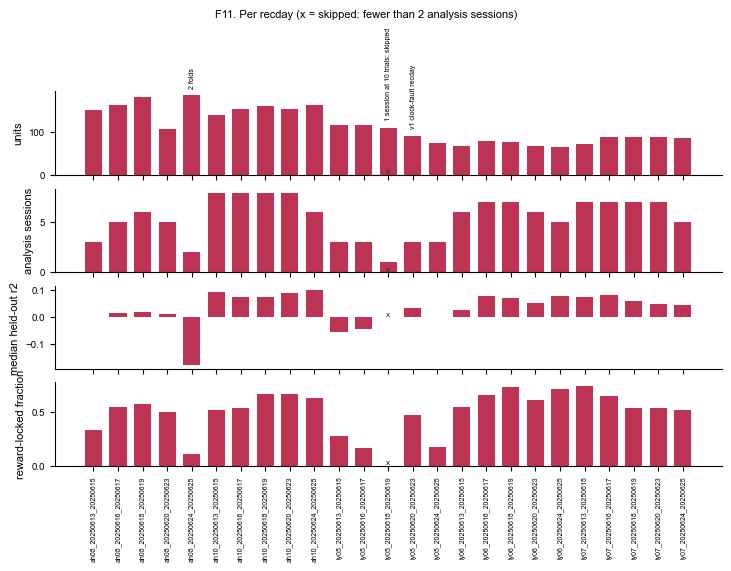

,recday,anchor,n_units,n_sessions,skipped,fold_rank_min,n_cols,n_rows,null_columns,rank_benign,r2_cv_median,reset,elapsed_s,slurm_job_id
0,ah08_20250613_20250615,entry,151,3,None,147.0,149.0,15010.0,ev_A:pre ev_reward:pre kin_missing:post,True,0.000160,ok,175.117891,3750345
1,ah08_20250616_20250617,entry,164,5,None,148.0,150.0,24681.0,ev_A:pre ev_reward:pre kin_missing:gap,True,0.016032,ok,463.117755,3750347
2,ah08_20250618_20250619,entry,183,6,None,147.0,149.0,30224.0,ev_A:pre ev_reward:pre kin_missing:post,True,0.016881,ok,719.340586,3750349
3,ah08_20250620_20250623,entry,108,5,None,147.0,149.0,25030.0,ev_A:pre ev_reward:pre kin_missing:pre_A,True,0.012528,ok,325.018163,3750351
4,ah08_20250624_20250625,entry,186,2,None,148.0,149.0,10206.0,ev_A:pre ev_reward:pre,True,-0.178946,ok,110.697312,3750353
5,ah10_20250613_20250615,entry,139,8,None,148.0,149.0,40406.0,ev_A:pre ev_reward:pre,True,0.091702,ok,1110.674702,3750355
6,ah10_20250616_20250617,entry,154,8,None,147.0,149.0,40379.0,ev_A:pre ev_reward:pre kin_missing:gap,True,0.072340,ok,1179.097076,3750357
7,ah10_20250618_20250619,entry,162,8,None,146.0,149.0,39688.0,ev_A:pre ev_reward:pre kin_missing:gap kin_mis...,True,0.074825,ok,1003.351273,3750359
8,ah10_20250620_20250623,entry,153,8,None,147.0,149.0,39072.0,ev_A:pre ev_reward:pre kin_missing:pre_A,True,0.089941,ok,1115.418121,3750361
9,ah10_20250624_20250625,entry,164,6,None,144.0,145.0,29321.0,ev_A:pre ev_reward:pre,True,0.101414,ok,687.575157,3750363


In [3]:
P.plot_recday_qc({'LEC': L}, out_path=fig_path('F11_recday_qc_LEC')); plt.show()
L['summary']

## F4. Kernel heatmaps: all LEC units, then each region (off-boundary units)

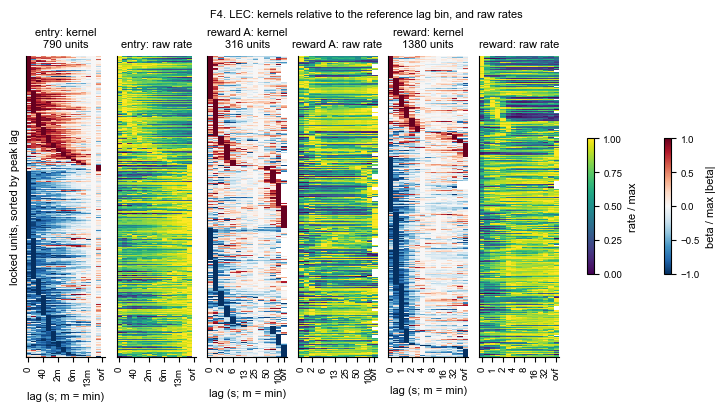

In [4]:
P.plot_kernel_heatmaps(L, 'LEC', out_path=fig_path('F4_kernels_LEC')); plt.show()

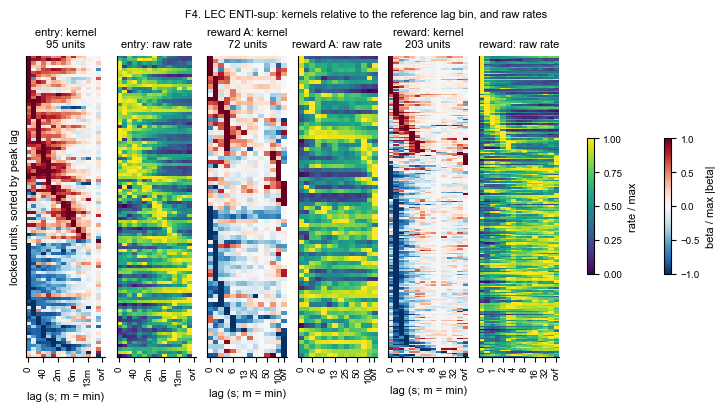

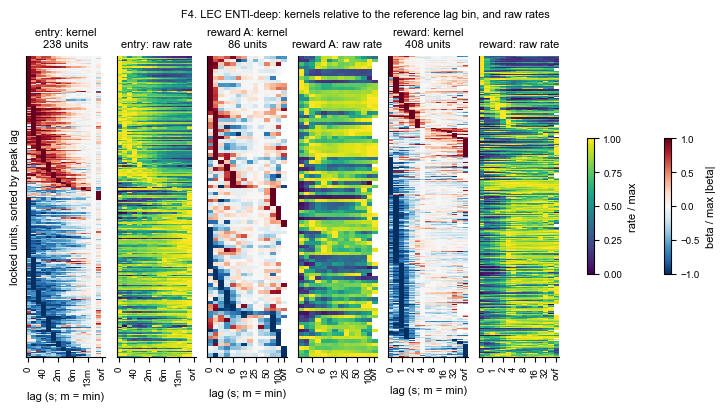

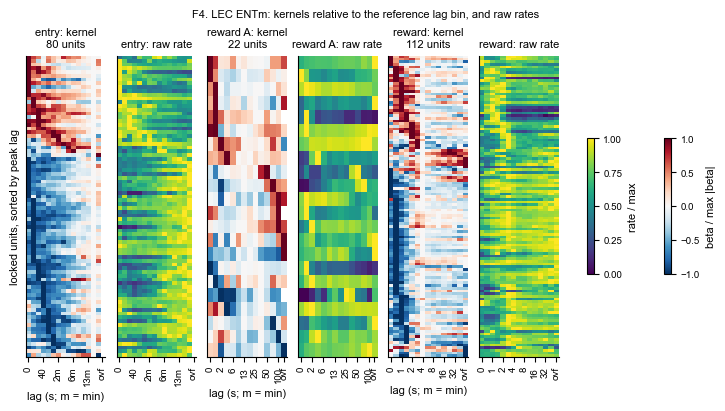

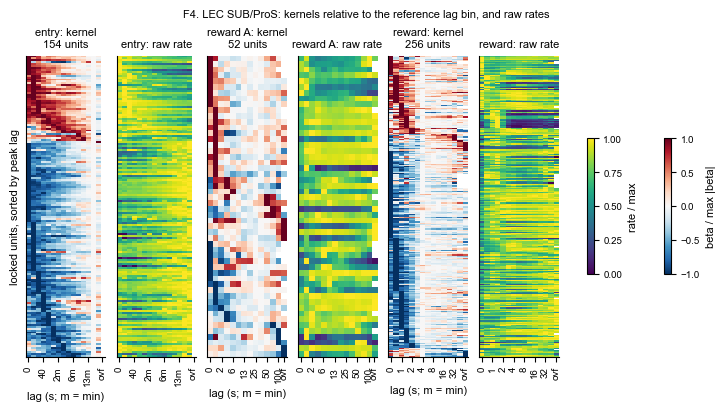

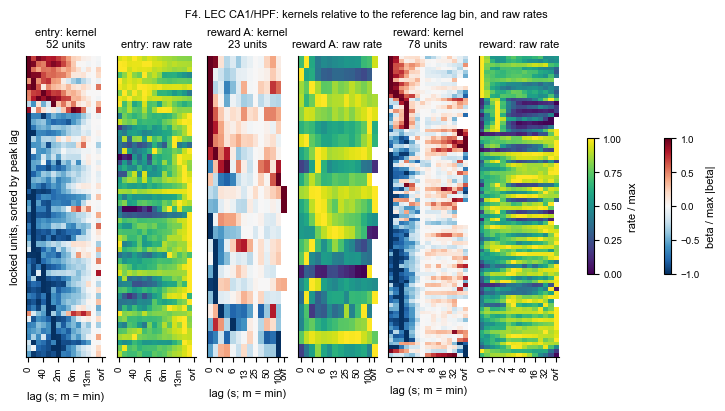

In [5]:
for g in P.REGION_ORDER:
    P.plot_kernel_heatmaps(L, f'LEC {g}', groups=[g], out_path=fig_path(f"F4_kernels_LEC_{g.replace('/', '-')}")); plt.show()

## F8. Threshold sensitivity: >= 10 vs >= 5 trials per session

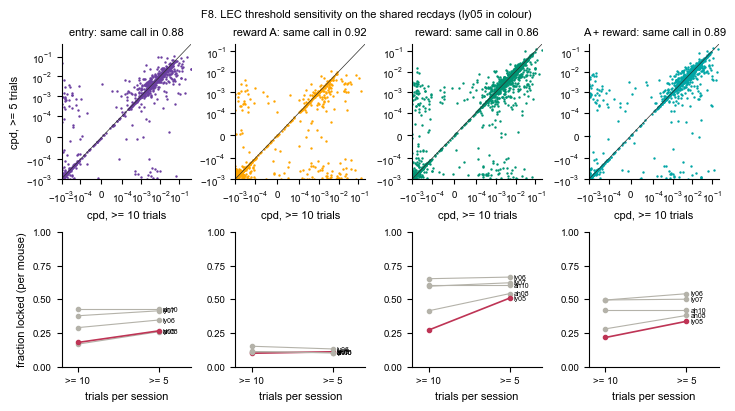

,block,mouse,n_recdays,n_units,fraction_10,fraction_5,agreement
0,ev_entry,ah08,5,792,0.167,0.259,0.795
1,ev_entry,ah10,5,772,0.426,0.426,1.000
2,ev_entry,ly05,4,398,0.180,0.266,0.746
3,ev_entry,ly06,5,356,0.290,0.346,0.876
4,ev_entry,ly07,5,424,0.378,0.415,0.941
5,ev_A,ah08,5,792,0.113,0.103,0.874
6,ev_A,ah10,5,772,0.110,0.110,1.000
7,ev_A,ly05,4,398,0.100,0.111,0.849
8,ev_A,ly06,5,356,0.152,0.132,0.902
9,ev_A,ly07,5,424,0.111,0.103,0.936


In [6]:
P.plot_threshold_sensitivity(L, L5, out_path=fig_path('F8_threshold_sensitivity')); plt.show()
P.table_threshold(L, L5).round(3)

## Population drift at both thresholds

In [7]:
K = P.table_knn({'LEC >= 10': D10, 'LEC >= 5': D5})
K[K['measure'].isin(['within_over_chance', 'across_over_chance'])].pivot_table(
    index=['dataset', 'set', 'group'], columns='measure', values='value', aggfunc='mean').round(2)

measure                        across_over_chance  within_over_chance
dataset   set       group                                            
LEC >= 10 all 20    all                      1.49                2.87
          region 20 CA1/HPF                  1.32                1.66
                    ENTl-deep                1.72                2.43
                    ENTl-sup                 1.50                3.68
                    ENTm                     1.59                3.04
                    SUB/ProS                 1.38                3.20
LEC >= 5  all 20    all                      1.54                3.05
          region 20 CA1/HPF                  1.35                1.92
                    ENTl-deep                1.74                2.63
                    ENTl-sup                 1.59                3.79
                    ENTm                     1.61                3.08
                    SUB/ProS                 1.43                3.24